## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Yipeng Cao]

**Date:** [10/14/26]

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd


def createData(noise, N=50):
    np.random.seed(100)  # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    df = pd.concat([gdf1, gdf2, gdf3], axis=0)
    return df


df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

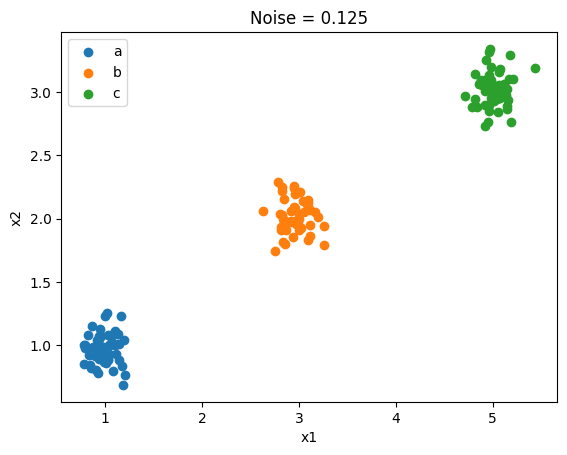

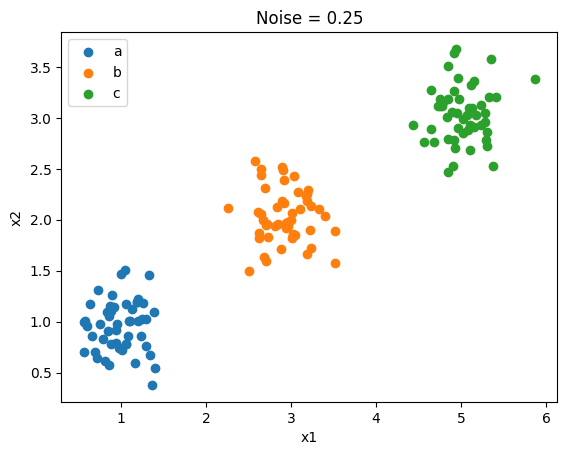

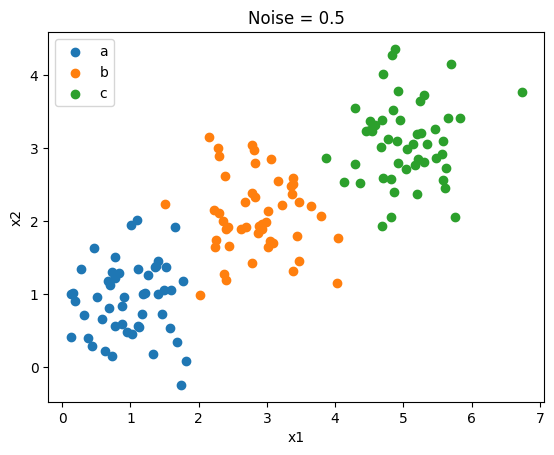

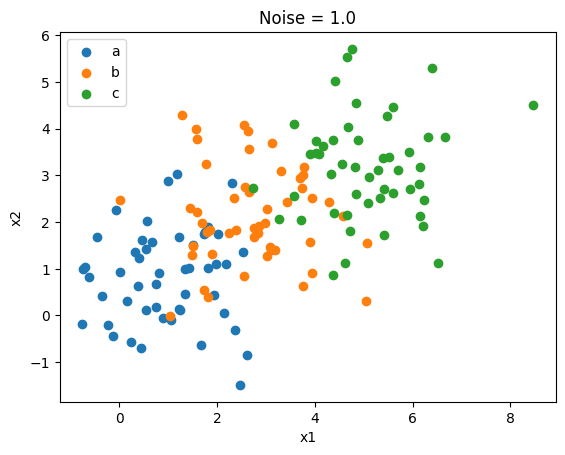

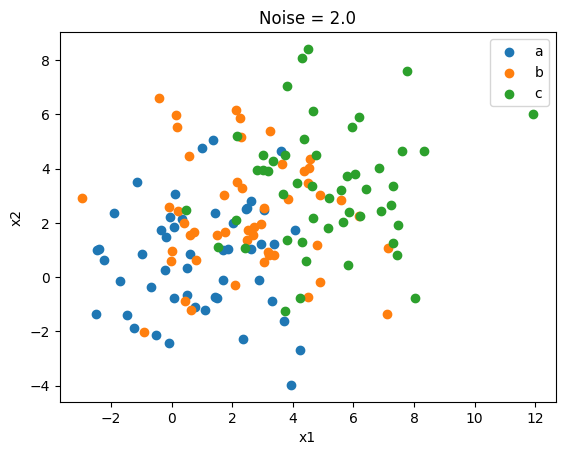

In [23]:
import matplotlib.pyplot as plt
datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(5):
    df = datasets[i]

    for group in ['a', 'b', 'c']:
        data = df[df['group'] == group]
        plt.scatter(data['x1'], data['x2'], label=group)

    plt.title(f"Noise = {noises[i]}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()


In [33]:
#As the noise increases, the visual differences of the clusters decreases. At lower noise levels 0.125 and 0.25, the clusters are well-separated. As the noise increases to 0.5, 1.0, and 2.0, the clusters start to overlap more, making it harder to distinguish between the different groups.

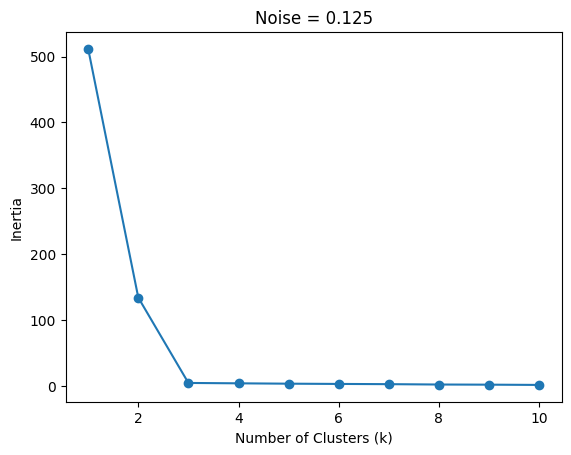

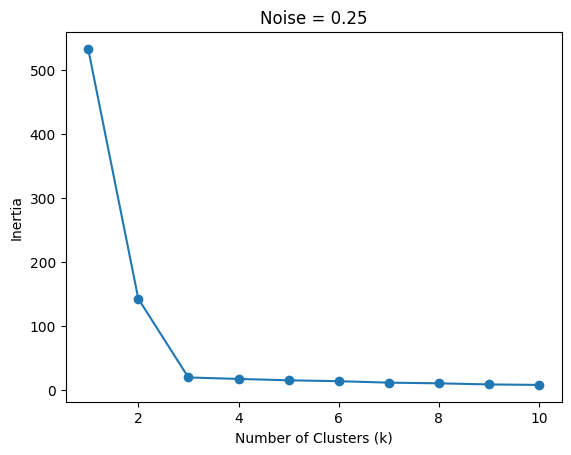

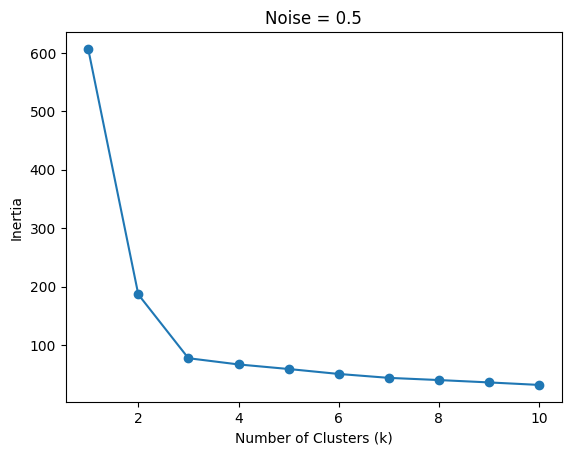

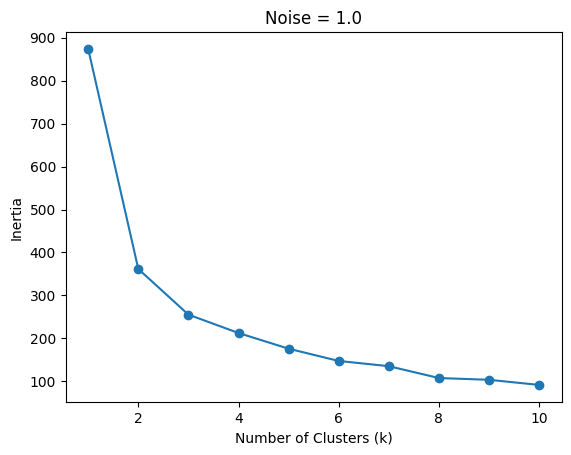

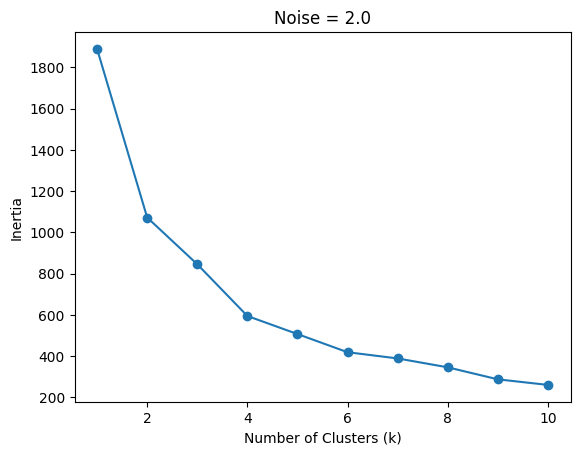

In [9]:
from sklearn.cluster import KMeans

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noises = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(5):
    df = datasets[i]
    X = df[['x1', 'x2']]

    inertia = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100)
        model.fit(X)
        inertia.append(model.inertia_)

    plt.plot(range(1, 11), inertia, marker='o')
    plt.title(f"Noise = {noises[i]}")
    plt.xlabel("Number of Clusters (k)")
    plt.ylabel("Inertia")
    plt.show()


In [ ]:
# As the noise increases, the elbow in the plots becomes less clear. At lower noise levels, there is a clear elbow at k = 3, making it easier to choose k. At higher noise levels, the elbow becomes less obvious, making it harder to choose the best k. By looking at the vertical axes of the plots we can tell the inertia values increase as the noise increases.

In [ ]:
# Part 4: The elbow is the point where increasing k no longer reduces inertia significantly. In this situation, there are three groups, so when k increases from 1 to 3, inertia decreases quickly. After k=3, the decrease becomes smaller because the three groups are already separated. As noise increases, the elbow becomes less clear because the groups overlap more.

In [49]:
#Q2:
import pandas as pd

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")

df = df[df["Year"] == 2020]

df = df.dropna()

print(df.shape)
print(df.dtypes)
print(df.head())

(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
     index  Year      Country  Spending (2020 USD)  Percent of GDP  \
32      32  2020  Afghanistan           279.576955        0.013589   
66      66  2020      Albania           187.433234        0.012583   
100    100  2020      Algeria          9708.277440        0.066600   
134    134  2020       Angola           993.594405        0.014442   
168    168  2020    Argentina          2830.929705        0.007269   

     Percent of Government Spending  Spending per Capita  
32                         0.049728             7.181899  
66                         0.037952            65.126211  
100                        0.173924           221.392384  
134                       

In [ ]:
#No further cleaning is needed.

In [50]:
from sklearn.preprocessing import MinMaxScaler
X = df[["Spending (2020 USD)", "Spending per Capita"]]

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

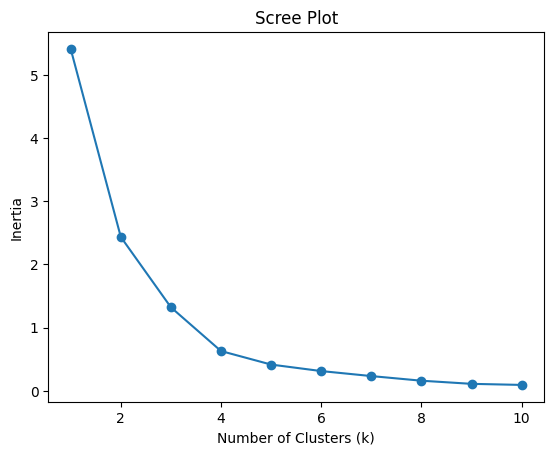

In [51]:
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot")
plt.show()


In [25]:
#Based on the scree plot, I chose k = 4 because after k = 4 the curve becomes flatter.

In [52]:
model = KMeans(n_clusters=4, random_state=100)
model.fit(X_scaled)
df["cluster"] = model.labels_

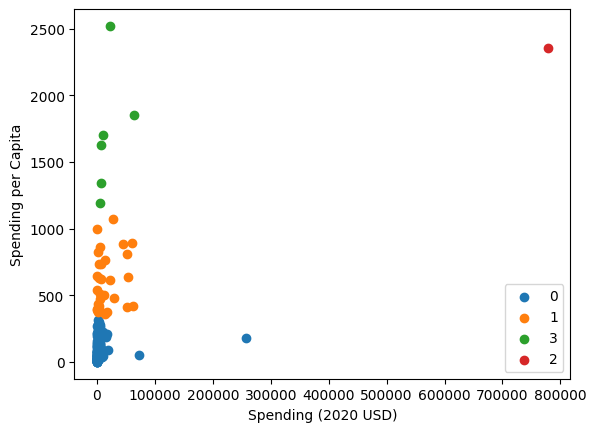

In [53]:
for cluster in df["cluster"].unique():
    data = df[df["cluster"] == cluster]

    plt.scatter(data["Spending (2020 USD)"],
                data["Spending per Capita"],
                label=cluster)

plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.legend()
plt.show()


In [54]:
df.groupby("cluster").describe()

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0        111.0  2768.540541  1665.488123    32.0  1205.0  2752.0  4112.0   
1         30.0  2782.600000  1664.320688   236.0  1494.0  2769.0  4307.5   
2          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
3          6.0  3783.333333   843.766476  2582.0  3194.0  4027.0  4375.5   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5880.0  111.0  2020.0  ...                       0.083508  0.303027   
1        5506.0   30.0  2020.0  ...                       0.048819  0.114776   
2        5540.0    1.0  2020.0  ...                       0.081976  0.081976   
3        4656.0    6.0  2020.0  ...                       0.164503  0.225050   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                     111.0    80.061470   83.501824     0.580129   
1                      30.0   607.478618  206.928757   362.467076   
2                       1.0  2351.631858         NaN  2351.631858   
3                       6.0  1706.721916  466.375705  1193.598730   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0          14.880549    47.056944   125.387558   314.201312  
1         422.208252   579.004604   757.328513  1070.623322  
2        2351.631858  2351.631858  2351.631858  2351.631858  
3        1412.083201  1665.447478  1817.219993  2520.398541  

[4 rows x 48 columns]

In [55]:
df[df["Country"] == "United States of America"]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2


In [ ]:
#Based on the graph and describe table, most countries are in cluster 0, which has relatively low total spending and spending per capita. Cluster 1 has higher spending per capita, while cluster 3 contains a few countries with high spending per capita. The United States is the only country in cluster 2, with the highest total spending. Overall, most countries have relatively low military spending, while only a few countries have higher spending.

In [56]:
X2 = df[["Percent of Government Spending", "Percent of GDP"]]
scaler = MinMaxScaler()
X2_scaled = scaler.fit_transform(X2)

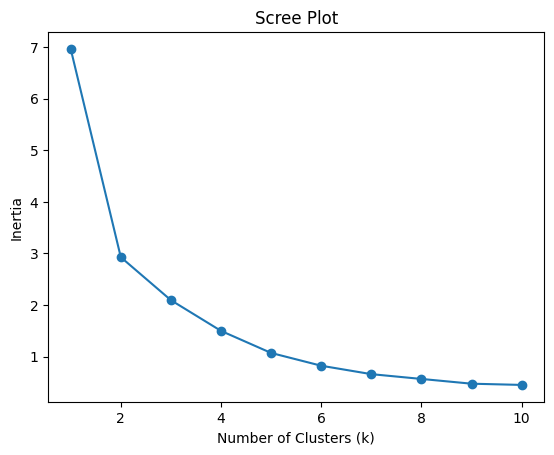

In [57]:
inertia2 = []

for k in range(1, 11):
    model2 = KMeans(n_clusters=k, random_state=100)
    model2.fit(X2_scaled)
    inertia2.append(model2.inertia_)

plt.plot(range(1, 11), inertia2, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot")
plt.show()

In [ ]:
#let k=2

In [59]:
model2 = KMeans(n_clusters=2, random_state=100)
model2.fit(X2_scaled)
df["cluster2"] = model2.labels_

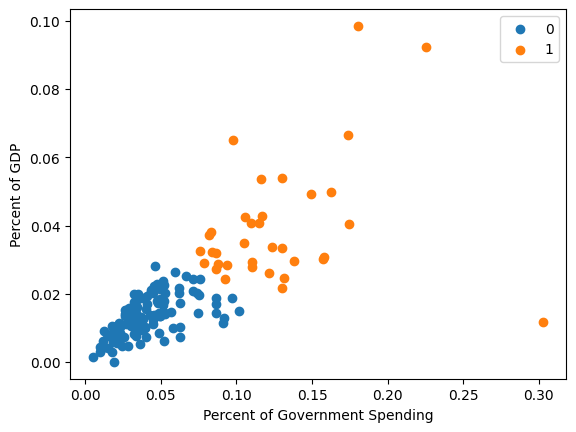

In [60]:
for cluster in df["cluster2"].unique():
    data = df[df["cluster2"] == cluster]

    plt.scatter(data["Percent of Government Spending"],
                data["Percent of GDP"],
                label=cluster)

plt.xlabel("Percent of Government Spending")
plt.ylabel("Percent of GDP")
plt.legend()
plt.show()

In [61]:
df.groupby("cluster2")[["Percent of Government Spending", "Percent of GDP"]].describe()

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster2                                                                
0                                 113.0  0.041394  0.020681  0.004896   
1                                  35.0  0.126456  0.046209  0.076005   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster2                                                                    
0         0.026783  0.038486  0.051496  0.101501          113.0  0.013481   
1         0.093093  0.116052  0.143584  0.303027           35.0  0.039433   

                                                                      
               std       min       25%       50%       75%       max  
cluster2                                                              
0         0.005966  0.000054  0.009147  0.013631  0.017830  0.028132  
1         0.018179  0.011742  0.028962  0.033281  0.042722  0.098470

In [62]:
df[df["Country"] == "United States of America"]

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster,cluster2
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,2,1


In [ ]:
# In this situation, Cluster 1 has 113 countries with lower military spending percentages, cluster 2 has 35 countries with higher percentages. In Part 2, we had 4 clusters, and the United States was in a cluster by itself. But in Part 3, the United States is not the only country in cluster 2. This shows that using different variables can change how countries are grouped.

In [63]:
X3 = df[["Spending (2020 USD)", "Spending per Capita","Percent of Government Spending", "Percent of GDP"]]
scaler = MinMaxScaler()
X3_scaled = scaler.fit_transform(X3)

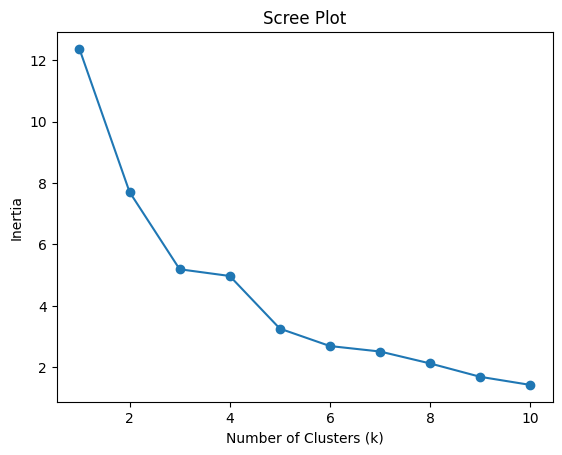

In [67]:
inertia3 = []

for k in range(1, 11):
    model3 = KMeans(n_clusters=k, random_state=100)
    model3.fit(X3_scaled)
    inertia3.append(model3.inertia_)

plt.plot(range(1, 11), inertia3, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Scree Plot")
plt.show()


In [ ]:
# let k=5

In [70]:
model3 = KMeans(n_clusters=5, random_state=100)
model3.fit(X3_scaled)
df["cluster3"] = model3.labels_

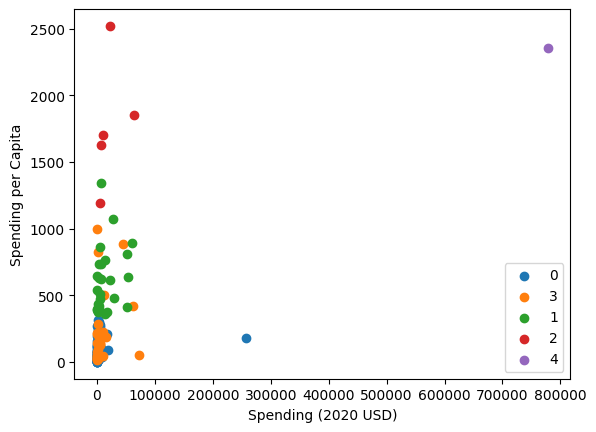

In [71]:
for cluster in df["cluster3"].unique():
    data = df[df["cluster3"] == cluster]

    plt.scatter(data["Spending (2020 USD)"],
                data["Spending per Capita"],
                label=cluster)

plt.xlabel("Spending (2020 USD)")
plt.ylabel("Spending per Capita")
plt.legend()
plt.show()


In [72]:
df.groupby("cluster3")[["Spending (2020 USD)","Spending per Capita","Percent of Government Spending","Percent of GDP"]].describe()

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster3                                                                   
0                       86.0    4513.543790  27841.230783       8.622460   
1                       26.0   15330.618681  18923.469359     405.790494   
2                        5.0   21878.058451  24674.937388    6095.708713   
3                       30.0    9073.543709  18135.032885     163.926877   
4                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster3                                                               
0             81.022976     288.061512    1138.618231  257973.429834   
1           3176.345598    5857.060906   21818.934764   60675.039625   
2           6941.042345    9978.571429   21816.569767   64558.400000   
3            522.737081    1663.090134    8646.648849   72937.064048   
4         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster3                                   ...                                  
0                       86.0    70.290644  ...                       0.053006   
1                       26.0   612.677541  ...                       0.044645   
2                        5.0  1779.854530  ...                       0.180654   
3                       30.0   215.920971  ...                       0.136403   
4                        1.0  2351.631858  ...                       0.081976   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster3                                                                    
0         0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1         0.052209           26.0  0.016585  0.005525  0.006273  0.013689   
2         0.225050            5.0  0.067725  0.028372  0.029429  0.053553   
3         0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
4         0.081976            1.0  0.037179       NaN  0.037179  0.037179   

                                        
               50%       75%       max  
cluster3                                
0         0.012532  0.016783  0.026340  
1         0.015324  0.020431  0.028132  
2         0.064961  0.092211  0.098470  
3         0.032148  0.040637  0.066600  
4         0.037179  0.037179  0.037179  

[5 rows x 32 columns]

In [73]:
df[df["Country"] == "United States of America"][["Country", "cluster", "cluster2", "cluster3"]]

,Country,cluster,cluster2,cluster3
5540,United States of America,2,1,4


In [ ]:
# In this case most countries are in cluster 0, while the other clusters have different levels of military spending. Compared to Part 2 and Part 3, Part 4 has more clusters. The United States is in cluster 4 by itself, which is similar to Part 2.

In [ ]:
#Q2 part 5: I think K-mc helped me find some useful patterns. Most countries have relatively low military spending, also a few other countries have higher military spending. The United States was in its own cluster in two senarios because of its high total spending. I also noticed that using different variables changes how countries are grouped. Overall, K-mc makes it easier to see the differences in military spending between countries.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [6c0a00a]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]